# Problem 2: Batch Normalization

In this notebook, you will implement the batch normalization layers of a neural network to increase its performance.  Please review the details of batch normalization from the lecture notes.

CS231n has built a solid API for building these modular frameworks and training them, and we will use their very well implemented framework as opposed to "reinventing the wheel."  This includes using their Solver, various utility functions, and their layer structure.  This also includes nndl.fc_net, nndl.layers, and nndl.layer_utils.  As in prior assignments, we thank Serena Yeung & Justin Johnson for permission to use code written for the CS 231n class (cs231n.stanford.edu).  

In [1]:
## Import and setups

import time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(231)

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# for auto-reloading external modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

def rel_error(x, y):
  """ returns relative error """
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

# Supplied gradient-check helpers (included here so Colab needs no extra files).
def eval_numerical_gradient(f, x, verbose=True, h=0.00001):
  """ 
  a naive implementation of numerical gradient of f at x 
  - f should be a function that takes a single argument
  - x is the point (numpy array) to evaluate the gradient at
  """ 

  fx = f(x) # evaluate function value at original point
  grad = np.zeros_like(x)
  # iterate over all indexes in x
  it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
  while not it.finished:

    # evaluate function at x+h
    ix = it.multi_index
    oldval = x[ix]
    x[ix] = oldval + h # increment by h
    fxph = f(x) # evalute f(x + h)
    x[ix] = oldval - h
    fxmh = f(x) # evaluate f(x - h)
    x[ix] = oldval # restore

    # compute the partial derivative with centered formula
    grad[ix] = (fxph - fxmh) / (2 * h) # the slope
    if verbose:
      print(ix, grad[ix])
    it.iternext() # step to next dimension

  return grad

def eval_numerical_gradient_array(f, x, df, h=1e-5):
  """
  Evaluate a numeric gradient for a function that accepts a numpy
  array and returns a numpy array.
  """
  grad = np.zeros_like(x)
  it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
  while not it.finished:
    ix = it.multi_index
    
    oldval = x[ix]
    x[ix] = oldval + h
    pos = f(x).copy()
    x[ix] = oldval - h
    neg = f(x).copy()
    x[ix] = oldval
    
    grad[ix] = np.sum((pos - neg) * df) / (2 * h)
    it.iternext()
  return grad


In [2]:
import hashlib
import pickle
import tarfile
from pathlib import Path
from urllib.request import urlretrieve


def load_CIFAR10(root):
    # Same image layout as the supplied cs231n loader, using float32 to save memory.
    def load_batch(filename):
        with open(Path(root) / filename, 'rb') as f:
            batch = pickle.load(f, encoding='latin1')
        images = batch['data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
        return images.astype(np.float32), np.array(batch['labels'])

    batches = [load_batch('data_batch_%d' % i) for i in range(1, 6)]
    X_train = np.concatenate([batch[0] for batch in batches])
    y_train = np.concatenate([batch[1] for batch in batches])
    X_test, y_test = load_batch('test_batch')
    return X_train, y_train, X_test, y_test


def prepare_CIFAR10():
    root = Path('cifar-10-batches-py')
    if not (root / 'test_batch').exists():
        archive = Path('cifar-10-python.tar.gz')
        if not archive.exists():
            print('Downloading CIFAR-10...')
            urlretrieve('https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz', archive)
        with open(archive, 'rb') as f:
            checksum = hashlib.file_digest(f, 'md5').hexdigest()
        if checksum != 'c58f30108f718f92721af3b95e74349a':
            raise ValueError('CIFAR-10 download is incomplete; remove the archive and rerun.')
        with tarfile.open(archive, 'r:gz') as f:
            f.extractall(path='.', filter='data')
    return root


def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000):
    """
    Load the CIFAR-10 dataset from disk and perform preprocessing to prepare
    it for the two-layer neural net classifier. These are the same steps as
    we used for the SVM, but condensed to a single function.
    """
    # Load the raw CIFAR-10 data
    cifar10_dir = prepare_CIFAR10()
    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

    # Subsample the data
    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]

    # Normalize the data: subtract the mean image
    mean_image = np.mean(X_train, axis=0)
    X_train -= mean_image
    X_val -= mean_image
    X_test -= mean_image

    # Reshape data to rows
    X_train = X_train.reshape(num_training, -1)
    X_val = X_val.reshape(num_validation, -1)
    X_test = X_test.reshape(num_test, -1)

    return {
        'X_train': X_train.reshape(-1, 32, 32, 3).transpose(0, 3, 1, 2).copy(),
        'y_train': y_train,
        'X_val': X_val.reshape(-1, 32, 32, 3).transpose(0, 3, 1, 2).copy(),
        'y_val': y_val,
        'X_test': X_test.reshape(-1, 32, 32, 3).transpose(0, 3, 1, 2).copy(),
        'y_test': y_test,
    }



# Load the same 49,000 / 1,000 / 1,000 split used in HW3.
# Reuse the arrays when running all three problems together.
if 'data' not in globals():
    data = get_CIFAR10_data()
for k, v in data.items():
    print(f"{k}: {v.shape}")


X_train: (49000, 3, 32, 32)
y_train: (49000,)
X_val: (1000, 3, 32, 32)
y_val: (1000,)
X_test: (1000, 3, 32, 32)
y_test: (1000,)


In [3]:
# Reused layer functions and the supplied Solver.
def affine_forward(x, w, b):
    x_flat = x.reshape(x.shape[0], -1)
    out = x_flat @ w + b
    return out, (x, w, b)


def affine_backward(dout, cache):
    x, w, b = cache
    x_flat = x.reshape(x.shape[0], -1)
    dx = (dout @ w.T).reshape(x.shape)
    dw = x_flat.T @ dout
    db = np.sum(dout, axis=0)
    return dx, dw, db


def relu_forward(x):
    return np.maximum(0, x), x


def relu_backward(dout, cache):
    return dout * (cache > 0)


def softmax_loss(x, y):
    # Work with log probabilities so large scores don't cause log(0).
    shifted = x - x.max(axis=1, keepdims=True)
    log_probs = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    N = x.shape[0]
    loss = -log_probs[np.arange(N), y].mean()
    dx = np.exp(log_probs)
    dx[np.arange(N), y] -= 1
    dx /= N
    return loss, dx

from builtins import range
from builtins import object
import os
from copy import deepcopy
import pickle as pickle

import numpy as np

from types import SimpleNamespace

def sgd(w, dw, config=None):
  """
  Performs vanilla stochastic gradient descent.

  config format:
  - learning_rate: Scalar learning rate.
  """
  if config is None: config = {}
  config.setdefault('learning_rate', 1e-2)

  w -= config['learning_rate'] * dw
  return w, config


def adam(w, dw, config=None):
  """
  Uses the Adam update rule, which incorporates moving averages of both the
  gradient and its square and a bias correction term.

  config format:
  - learning_rate: Scalar learning rate.
  - beta1: Decay rate for moving average of first moment of gradient.
  - beta2: Decay rate for moving average of second moment of gradient.
  - epsilon: Small scalar used for smoothing to avoid dividing by zero.
  - v: Moving average of gradient.
  - a: Moving average of squared gradient.
  - t: Iteration number.
  """
  if config is None: config = {}
  config.setdefault('learning_rate', 1e-3)
  config.setdefault('beta1', 0.9)
  config.setdefault('beta2', 0.999)
  config.setdefault('epsilon', 1e-8)
  config.setdefault('v', np.zeros_like(w))
  config.setdefault('a', np.zeros_like(w))
  config.setdefault('t', 0)

  next_w = None


  beta1, beta2 = config['beta1'], config['beta2']
  config['t'] += 1
  config['v'] = beta1 * config['v'] + (1 - beta1) * dw
  config['a'] = beta2 * config['a'] + (1 - beta2) * dw**2

  v_hat = config['v'] / (1 - beta1**config['t'])
  a_hat = config['a'] / (1 - beta2**config['t'])
  next_w = w - config['learning_rate'] * v_hat / (np.sqrt(a_hat) + config['epsilon'])


  return next_w, config

optim = SimpleNamespace(sgd=sgd, adam=adam)


class Solver(object):
    """
    A Solver encapsulates all the logic necessary for training classification
    models. The Solver performs stochastic gradient descent using different
    update rules defined in optim.py.

    The solver accepts both training and validataion data and labels so it can
    periodically check classification accuracy on both training and validation
    data to watch out for overfitting.

    To train a model, you will first construct a Solver instance, passing the
    model, dataset, and various optoins (learning rate, batch size, etc) to the
    constructor. You will then call the train() method to run the optimization
    procedure and train the model.

    After the train() method returns, model.params will contain the parameters
    that performed best on the validation set over the course of training.
    In addition, the instance variable solver.loss_history will contain a list
    of all losses encountered during training and the instance variables
    solver.train_acc_history and solver.val_acc_history will be lists of the
    accuracies of the model on the training and validation set at each epoch.

    Example usage might look something like this:

    data = {
      'X_train': # training data
      'y_train': # training labels
      'X_val': # validation data
      'y_val': # validation labels
    }
    model = MyAwesomeModel(hidden_size=100, reg=10)
    solver = Solver(model, data,
                    update_rule='sgd',
                    optim_config={
                      'learning_rate': 1e-3,
                    },
                    lr_decay=0.95,
                    num_epochs=10, batch_size=100,
                    print_every=100)
    solver.train()


    A Solver works on a model object that must conform to the following API:

    - model.params must be a dictionary mapping string parameter names to numpy
      arrays containing parameter values.

    - model.loss(X, y) must be a function that computes training-time loss and
      gradients, and test-time classification scores, with the following inputs
      and outputs:

      Inputs:
      - X: Array giving a minibatch of input data of shape (N, d_1, ..., d_k)
      - y: Array of labels, of shape (N,) giving labels for X where y[i] is the
        label for X[i].

      Returns:
      If y is None, run a test-time forward pass and return:
      - scores: Array of shape (N, C) giving classification scores for X where
        scores[i, c] gives the score of class c for X[i].

      If y is not None, run a training time forward and backward pass and
      return a tuple of:
      - loss: Scalar giving the loss
      - grads: Dictionary with the same keys as self.params mapping parameter
        names to gradients of the loss with respect to those parameters.
    """

    def __init__(self, model, data, **kwargs):
        """
        Construct a new Solver instance.

        Required arguments:
        - model: A model object conforming to the API described above
        - data: A dictionary of training and validation data containing:
          'X_train': Array, shape (N_train, d_1, ..., d_k) of training images
          'X_val': Array, shape (N_val, d_1, ..., d_k) of validation images
          'y_train': Array, shape (N_train,) of labels for training images
          'y_val': Array, shape (N_val,) of labels for validation images

        Optional arguments:
        - update_rule: A string giving the name of an update rule in optim.py.
          Default is 'sgd'.
        - optim_config: A dictionary containing hyperparameters that will be
          passed to the chosen update rule. Each update rule requires different
          hyperparameters (see optim.py) but all update rules require a
          'learning_rate' parameter so that should always be present.
        - lr_decay: A scalar for learning rate decay; after each epoch the
          learning rate is multiplied by this value.
        - batch_size: Size of minibatches used to compute loss and gradient
          during training.
        - num_epochs: The number of epochs to run for during training.
        - print_every: Integer; training losses will be printed every
          print_every iterations.
        - verbose: Boolean; if set to false then no output will be printed
          during training.
        - num_train_samples: Number of training samples used to check training
          accuracy; default is 1000; set to None to use entire training set.
        - num_val_samples: Number of validation samples to use to check val
          accuracy; default is None, which uses the entire validation set.
        - checkpoint_name: If not None, then save model checkpoints here every
          epoch.
        """
        self.model = model
        self.X_train = data['X_train']
        self.y_train = data['y_train']
        self.X_val = data['X_val']
        self.y_val = data['y_val']

        # Unpack keyword arguments
        self.update_rule = kwargs.pop('update_rule', 'sgd')
        self.optim_config = kwargs.pop('optim_config', {})
        self.lr_decay = kwargs.pop('lr_decay', 1.0)
        self.batch_size = kwargs.pop('batch_size', 100)
        self.num_epochs = kwargs.pop('num_epochs', 10)
        self.num_train_samples = kwargs.pop('num_train_samples', 1000)
        self.num_val_samples = kwargs.pop('num_val_samples', None)

        self.checkpoint_name = kwargs.pop('checkpoint_name', None)
        self.print_every = kwargs.pop('print_every', 10)
        self.verbose = kwargs.pop('verbose', True)

        # Throw an error if there are extra keyword arguments
        if len(kwargs) > 0:
            extra = ', '.join('"%s"' % k for k in list(kwargs.keys()))
            raise ValueError('Unrecognized arguments %s' % extra)

        # Make sure the update rule exists, then replace the string
        # name with the actual function
        if not hasattr(optim, self.update_rule):
            raise ValueError('Invalid update_rule "%s"' % self.update_rule)
        self.update_rule = getattr(optim, self.update_rule)

        self._reset()


    def _reset(self):
        """
        Set up some book-keeping variables for optimization. Don't call this
        manually.
        """
        # Set up some variables for book-keeping
        self.epoch = 0
        self.best_val_acc = -np.inf
        self.best_params = {}
        self.best_bn_params = None
        self.loss_history = []
        self.train_acc_history = []
        self.val_acc_history = []

        # Make a deep copy of the optim_config for each parameter
        self.optim_configs = {}
        for p in self.model.params:
            d = {k: v for k, v in self.optim_config.items()}
            self.optim_configs[p] = d


    def _step(self):
        """
        Make a single gradient update. This is called by train() and should not
        be called manually.
        """
        # Make a minibatch of training data
        num_train = self.X_train.shape[0]
        batch_mask = np.random.choice(num_train, self.batch_size)
        X_batch = self.X_train[batch_mask]
        y_batch = self.y_train[batch_mask]

        # Compute loss and gradient
        loss, grads = self.model.loss(X_batch, y_batch)
        self.loss_history.append(loss)

        # Perform a parameter update
        for p, w in self.model.params.items():
            dw = grads[p]
            config = self.optim_configs[p]
            next_w, next_config = self.update_rule(w, dw, config)
            self.model.params[p] = next_w
            self.optim_configs[p] = next_config


    def _save_checkpoint(self):
        if self.checkpoint_name is None: return
        checkpoint = {
          'model': self.model,
          'update_rule': self.update_rule,
          'lr_decay': self.lr_decay,
          'optim_config': self.optim_config,
          'batch_size': self.batch_size,
          'num_train_samples': self.num_train_samples,
          'num_val_samples': self.num_val_samples,
          'epoch': self.epoch,
          'loss_history': self.loss_history,
          'train_acc_history': self.train_acc_history,
          'val_acc_history': self.val_acc_history,
        }
        filename = '%s_epoch_%d.pkl' % (self.checkpoint_name, self.epoch)
        if self.verbose:
            print('Saving checkpoint to "%s"' % filename)
        with open(filename, 'wb') as f:
            pickle.dump(checkpoint, f)


    def check_accuracy(self, X, y, num_samples=None, batch_size=100):
        """
        Check accuracy of the model on the provided data.

        Inputs:
        - X: Array of data, of shape (N, d_1, ..., d_k)
        - y: Array of labels, of shape (N,)
        - num_samples: If not None, subsample the data and only test the model
          on num_samples datapoints.
        - batch_size: Split X and y into batches of this size to avoid using
          too much memory.

        Returns:
        - acc: Scalar giving the fraction of instances that were correctly
          classified by the model.
        """

        # Maybe subsample the data
        N = X.shape[0]
        if num_samples is not None and N > num_samples:
            mask = np.random.choice(N, num_samples)
            N = num_samples
            X = X[mask]
            y = y[mask]

        # Compute predictions in batches
        num_batches = N // batch_size
        if N % batch_size != 0:
            num_batches += 1
        y_pred = []
        for i in range(num_batches):
            start = i * batch_size
            end = (i + 1) * batch_size
            scores = self.model.loss(X[start:end])
            y_pred.append(np.argmax(scores, axis=1))
        y_pred = np.hstack(y_pred)
        acc = np.mean(y_pred == y)

        return acc


    def train(self):
        """
        Run optimization to train the model.
        """
        num_train = self.X_train.shape[0]
        iterations_per_epoch = max(num_train // self.batch_size, 1)
        num_iterations = self.num_epochs * iterations_per_epoch

        for t in range(num_iterations):
            self._step()

            # Maybe print training loss
            if self.verbose and t % self.print_every == 0:
                print('(Iteration %d / %d) loss: %f' % (
                       t + 1, num_iterations, self.loss_history[-1]))

            # At the end of every epoch, increment the epoch counter and decay
            # the learning rate.
            epoch_end = (t + 1) % iterations_per_epoch == 0
            if epoch_end:
                self.epoch += 1
                for k in self.optim_configs:
                    self.optim_configs[k]['learning_rate'] *= self.lr_decay

            # Check train and val accuracy on the first iteration, the last
            # iteration, and at the end of each epoch.
            first_it = (t == 0)
            last_it = (t == num_iterations - 1)
            if first_it or last_it or epoch_end:
                train_acc = self.check_accuracy(self.X_train, self.y_train,
                    num_samples=self.num_train_samples)
                val_acc = self.check_accuracy(self.X_val, self.y_val,
                    num_samples=self.num_val_samples)
                self.train_acc_history.append(train_acc)
                self.val_acc_history.append(val_acc)
                self._save_checkpoint()

                if self.verbose:
                    print('(Epoch %d / %d) train acc: %f; val_acc: %f' % (
                           self.epoch, self.num_epochs, train_acc, val_acc))

                # Keep track of the best model
                if val_acc > self.best_val_acc:
                    self.best_val_acc = val_acc
                    self.best_params = {}
                    for k, v in self.model.params.items():
                        self.best_params[k] = v.copy()
                    # Running statistics belong to the same epoch as the weights.
                    self.best_bn_params = deepcopy(getattr(self.model, 'bn_params', None))

        # At the end of training swap the best params into the model
        self.model.params = self.best_params
        if self.best_bn_params is not None:
            self.model.bn_params = deepcopy(self.best_bn_params)


## Batchnorm forward pass

Implement the training time batchnorm forward pass, `batchnorm_forward`, in `nndl/layers.py`. After that, test your implementation by running the following cell.

In [4]:
def batchnorm_forward(x, gamma, beta, bn_param):
    mode = bn_param['mode']
    eps = bn_param.get('eps', 1e-5)
    momentum = bn_param.get('momentum', 0.9)
    running_mean = bn_param.get('running_mean', np.zeros(x.shape[1], dtype=x.dtype))
    running_var = bn_param.get('running_var', np.zeros(x.shape[1], dtype=x.dtype))
    cache = None

    if mode == 'train':
        mean = x.mean(axis=0)
        var = x.var(axis=0)
        centered = x - mean
        inv_std = 1 / np.sqrt(var + eps)
        x_hat = centered * inv_std
        out = gamma * x_hat + beta
        cache = (centered, x_hat, inv_std, gamma)
        running_mean = momentum * running_mean + (1 - momentum) * mean
        running_var = momentum * running_var + (1 - momentum) * var
    elif mode == 'test':
        out = gamma * (x - running_mean) / np.sqrt(running_var + eps) + beta
    else:
        raise ValueError('Invalid batchnorm mode: %s' % mode)

    bn_param['running_mean'] = running_mean
    bn_param['running_var'] = running_var
    return out, cache


In [5]:
# Check the training-time forward pass by checking means and variances
# of features both before and after batch normalization
# Verify the implementation by checking if the output matches the 
# statistical properties derived in the lecture notes.

# Simulate the forward pass for a two-layer network
N, D1, D2, D3 = 200, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)

print('Before batch normalization:')
print('  means: ', a.mean(axis=0))
print('  stds: ', a.std(axis=0))

# Means should be close to zero and stds close to one
print('After batch normalization (gamma=1, beta=0)')
a_norm, _ = batchnorm_forward(a, np.ones(D3), np.zeros(D3), {'mode': 'train'})
print('  mean: ', a_norm.mean(axis=0))
print('  std: ', a_norm.std(axis=0))

# Now means should be close to beta and stds close to gamma
gamma = np.asarray([1.0, 2.0, 3.0])
beta = np.asarray([11.0, 12.0, 13.0])
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print('After batch normalization (nontrivial gamma, beta)')
print('  means: ', a_norm.mean(axis=0))
print('  stds: ', a_norm.std(axis=0))

Before batch normalization:
  means:  [ -2.3814598  -13.18038246   1.91780462]
  stds:  [27.18502186 34.21455511 37.68611762]
After batch normalization (gamma=1, beta=0)
  mean:  [1.99840144e-17 2.05391260e-17 5.41927614e-17]
  std:  [0.99999999 1.         1.        ]
After batch normalization (nontrivial gamma, beta)
  means:  [11. 12. 13.]
  stds:  [0.99999999 1.99999999 2.99999999]


Implement the testing time batchnorm forward pass, `batchnorm_forward`, in `nndl/layers.py`. After that, test your implementation by running the following cell.

In [6]:
# Check the test-time forward pass by running the training-time
# forward pass many times to warm up the running averages, and then
# checking the means and variances of activations after a test-time
# forward pass.

N, D1, D2, D3 = 200, 50, 60, 3
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)

bn_param = {'mode': 'train'}
gamma = np.ones(D3)
beta = np.zeros(D3)
for t in np.arange(50):
  X = np.random.randn(N, D1)
  a = np.maximum(0, X.dot(W1)).dot(W2)
  batchnorm_forward(a, gamma, beta, bn_param)
bn_param['mode'] = 'test'
X = np.random.randn(N, D1)
a = np.maximum(0, X.dot(W1)).dot(W2)
a_norm, _ = batchnorm_forward(a, gamma, beta, bn_param)

# Means should be close to zero and stds close to one, but will be
# noisier than training-time forward passes.
print('After batch normalization (test-time):')
print('  means: ', a_norm.mean(axis=0))
print('  stds: ', a_norm.std(axis=0))

After batch normalization (test-time):
  means:  [ 0.12748897 -0.03074085  0.00991488]
  stds:  [1.00345532 0.89302211 0.96265855]


## Batchnorm backward pass

Implement the backward pass for the batchnorm layer, `batchnorm_backward` in `nndl/layers.py`.  Check your implementation by running the following cell.

In [5]:
def batchnorm_backward(dout, cache):
    centered, x_hat, inv_std, gamma = cache
    N = dout.shape[0]
    dbeta = dout.sum(axis=0)
    dgamma = np.sum(dout * x_hat, axis=0)

    # Go backward through the scale, normalization, variance, and mean.
    dx_hat = dout * gamma
    dvar = np.sum(dx_hat * centered, axis=0) * (-0.5) * inv_std**3
    dmean = -np.sum(dx_hat * inv_std, axis=0) - 2 * dvar * centered.mean(axis=0)
    dx = dx_hat * inv_std + 2 * centered * dvar / N + dmean / N
    return dx, dgamma, dbeta


In [8]:
# Gradient check batchnorm backward pass
# If your implementation is correct, the relative error should be very small (e.g., < 1e-7).

N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {'mode': 'train'}
fx = lambda x: batchnorm_forward(x, gamma, beta, bn_param)[0]
fg = lambda gamma: batchnorm_forward(x, gamma, beta, bn_param)[0]
fb = lambda beta: batchnorm_forward(x, gamma, beta, bn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma, dout)
db_num = eval_numerical_gradient_array(fb, beta, dout)

_, cache = batchnorm_forward(x, gamma, beta, bn_param)
dx, dgamma, dbeta = batchnorm_backward(dout, cache)
print('dx error: ', rel_error(dx_num, dx))
print('dgamma error: ', rel_error(da_num, dgamma))
print('dbeta error: ', rel_error(db_num, dbeta))

dx error:  9.549874879941822e-09
dgamma error:  2.4365651573243576e-11
dbeta error:  3.8897709532291015e-12


## Implement a fully connected neural network with batchnorm layers

Modify the `FullyConnectedNet()` class in `nndl/fc_net.py` to incorporate batchnorm layers.  You will need to modify the class in the following areas:

(1) The gammas and betas need to be initialized to 1's and 0's respectively in `__init__`.

(2) The `batchnorm_forward` layer needs to be inserted between each affine and relu layer (except in the output layer) in a forward pass computation in `loss`.  You may find it helpful to write an `affine_batchnorm_relu()` layer in `nndl/layer_utils.py` although this is not necessary.

(3) The `batchnorm_backward` layer has to be appropriately inserted when calculating gradients.

After you have done the appropriate modifications, check your implementation by running the following cell.

Note, while the relative error for W3 should be small, as we backprop gradients more, you may find the relative error increases.  Our relative error for W1 is on the order of 1e-5 to 1e-4.

In [6]:
class FullyConnectedNet:
    def __init__(self, hidden_dims, input_dim=3*32*32, num_classes=10,
                 dropout=1, use_batchnorm=False, reg=0.0,
                 weight_scale=1e-2, dtype=np.float32, seed=None):
        if not 0 < dropout <= 1:
            raise ValueError('dropout is a keep probability in (0, 1].')
        self.use_batchnorm = use_batchnorm
        self.use_dropout = dropout < 1
        self.reg = reg
        self.dtype = dtype
        self.num_layers = len(hidden_dims) + 1
        self.params = {}
        dims = [input_dim] + list(hidden_dims) + [num_classes]
        for i in range(1, self.num_layers + 1):
            self.params['W%d' % i] = (weight_scale * np.random.randn(dims[i-1], dims[i])).astype(dtype)
            self.params['b%d' % i] = np.zeros(dims[i], dtype=dtype)
            if use_batchnorm and i < self.num_layers:
                self.params['gamma%d' % i] = np.ones(dims[i], dtype=dtype)
                self.params['beta%d' % i] = np.zeros(dims[i], dtype=dtype)

        self.bn_params = [{'mode': 'train'} for _ in hidden_dims] if use_batchnorm else []
        self.dropout_param = {'mode': 'train', 'p': dropout}
        if seed is not None:
            self.dropout_param['seed'] = seed

    def loss(self, X, y=None):
        mode = 'test' if y is None else 'train'
        self.dropout_param['mode'] = mode
        for bn_param in self.bn_params:
            bn_param['mode'] = mode

        out = X.astype(self.dtype, copy=False)
        caches = {}
        for i in range(1, self.num_layers):
            out, fc_cache = affine_forward(out, self.params['W%d' % i], self.params['b%d' % i])
            bn_cache = None
            if self.use_batchnorm:
                out, bn_cache = batchnorm_forward(out, self.params['gamma%d' % i],
                                                  self.params['beta%d' % i], self.bn_params[i-1])
            out, relu_cache = relu_forward(out)
            drop_cache = None
            if self.use_dropout:
                drop_param = self.dropout_param.copy()
                if 'seed' in drop_param:
                    drop_param['seed'] += i - 1
                out, drop_cache = dropout_forward(out, drop_param)
            caches[i] = (fc_cache, bn_cache, relu_cache, drop_cache)

        L = self.num_layers
        scores, caches[L] = affine_forward(out, self.params['W%d' % L], self.params['b%d' % L])
        if y is None:
            return scores

        loss, dout = softmax_loss(scores, y)
        grads = {}
        for i in range(L, 0, -1):
            W = self.params['W%d' % i]
            loss += 0.5 * self.reg * np.sum(W**2)
            if i == L:
                dout, dW, db = affine_backward(dout, caches[i])
            else:
                fc_cache, bn_cache, relu_cache, drop_cache = caches[i]
                if self.use_dropout:
                    dout = dropout_backward(dout, drop_cache)
                dout = relu_backward(dout, relu_cache)
                if self.use_batchnorm:
                    dout, dgamma, dbeta = batchnorm_backward(dout, bn_cache)
                    grads['gamma%d' % i] = dgamma
                    grads['beta%d' % i] = dbeta
                dout, dW, db = affine_backward(dout, fc_cache)
            grads['W%d' % i] = dW + self.reg * W
            grads['b%d' % i] = db
        return loss, grads


In [10]:
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
  print('Running check with reg = ', reg)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            reg=reg, weight_scale=5e-2, dtype=np.float64,
                            use_batchnorm=True)

  loss, grads = model.loss(X, y)
  print('Initial loss: ', loss)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('{} relative error: {}'.format(name, rel_error(grad_num, grads[name])))
  if reg == 0: print('\n')

Running check with reg =  0
Initial loss:  2.242251524844593
W1 relative error: 0.0004975782550077781


W2 relative error: 3.32005076777778e-06


W3 relative error: 3.071818996852267e-10
b1 relative error: 1.1102230246251565e-08
b2 relative error: 2.220446049250313e-08
b3 relative error: 7.859267394125345e-11
beta1 relative error: 2.465695514882375e-08
beta2 relative error: 5.221852790718982e-09


gamma1 relative error: 3.584972529676799e-08
gamma2 relative error: 1.5844035441482324e-08


Running check with reg =  3.14
Initial loss:  7.209465971922538
W1 relative error: 1.9710443551408005e-07
W2 relative error: 2.1284686187811405e-06
W3 relative error: 1.5766592057614063e-08
b1 relative error: 3.469446951953614e-10
b2 relative error: 1.1102230246251565e-08
b3 relative error: 4.671559182099266e-10
beta1 relative error: 9.771415419830136e-08
beta2 relative error: 1.1866182983641096e-07
gamma1 relative error: 2.6719098643857606e-07
gamma2 relative error: 1.1318995328528469e-07


## Training a deep fully connected network with batch normalization.

To see if batchnorm helps, let's train a deep neural network with and without batch normalization.

In [11]:
# Same initial weights and minibatches for the two models.
hidden_dims = [100, 100, 100, 100, 100]
num_train = 1000
small_data = {
    'X_train': data['X_train'][:num_train],
    'y_train': data['y_train'][:num_train],
    'X_val': data['X_val'],
    'y_val': data['y_val'],
}
weight_scale = 2e-2
np.random.seed(231)
bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, use_batchnorm=True)
np.random.seed(231)
model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale)

np.random.seed(232)
bn_solver = Solver(bn_model, small_data, num_epochs=10, batch_size=50,
                   update_rule='adam', optim_config={'learning_rate': 1e-3},
                   verbose=True, print_every=200)
bn_solver.train()
np.random.seed(232)
solver = Solver(model, small_data, num_epochs=10, batch_size=50,
                update_rule='adam', optim_config={'learning_rate': 1e-3},
                verbose=True, print_every=200)
solver.train()
print(f"Best validation accuracy: baseline={solver.best_val_acc:.1%}, batchnorm={bn_solver.best_val_acc:.1%}")


(Iteration 1 / 200) loss: 2.336334
(Epoch 0 / 10) train acc: 0.102000; val_acc: 0.107000
(Epoch 1 / 10) train acc: 0.300000; val_acc: 0.237000
(Epoch 2 / 10) train acc: 0.426000; val_acc: 0.307000


(Epoch 3 / 10) train acc: 0.512000; val_acc: 0.348000
(Epoch 4 / 10) train acc: 0.567000; val_acc: 0.313000
(Epoch 5 / 10) train acc: 0.625000; val_acc: 0.320000


(Epoch 6 / 10) train acc: 0.683000; val_acc: 0.342000
(Epoch 7 / 10) train acc: 0.698000; val_acc: 0.323000
(Epoch 8 / 10) train acc: 0.762000; val_acc: 0.309000


(Epoch 9 / 10) train acc: 0.814000; val_acc: 0.316000
(Epoch 10 / 10) train acc: 0.801000; val_acc: 0.303000
(Iteration 1 / 200) loss: 2.303009
(Epoch 0 / 10) train acc: 0.121000; val_acc: 0.124000
(Epoch 1 / 10) train acc: 0.195000; val_acc: 0.175000


(Epoch 2 / 10) train acc: 0.270000; val_acc: 0.252000
(Epoch 3 / 10) train acc: 0.303000; val_acc: 0.252000
(Epoch 4 / 10) train acc: 0.343000; val_acc: 0.268000


(Epoch 5 / 10) train acc: 0.408000; val_acc: 0.291000
(Epoch 6 / 10) train acc: 0.413000; val_acc: 0.286000
(Epoch 7 / 10) train acc: 0.505000; val_acc: 0.315000


(Epoch 8 / 10) train acc: 0.508000; val_acc: 0.282000
(Epoch 9 / 10) train acc: 0.572000; val_acc: 0.315000
(Epoch 10 / 10) train acc: 0.625000; val_acc: 0.304000
Best validation accuracy: baseline=31.5%, batchnorm=34.8%


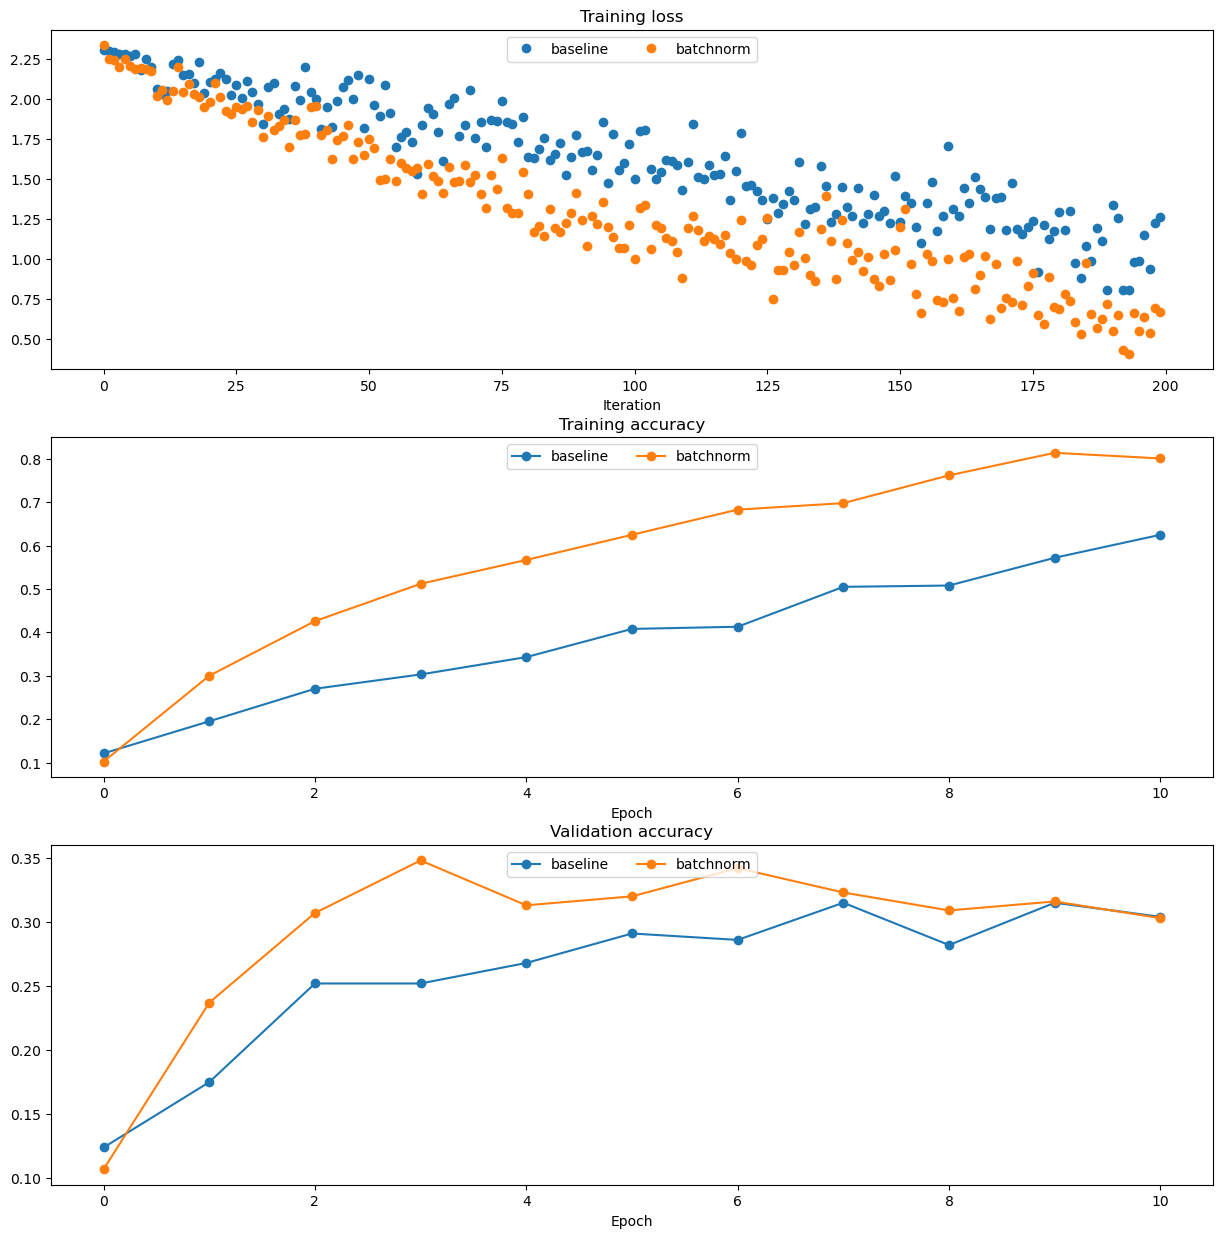

In [12]:
plt.subplot(3, 1, 1)
plt.title('Training loss')
plt.xlabel('Iteration')

plt.subplot(3, 1, 2)
plt.title('Training accuracy')
plt.xlabel('Epoch')

plt.subplot(3, 1, 3)
plt.title('Validation accuracy')
plt.xlabel('Epoch')

plt.subplot(3, 1, 1)
plt.plot(solver.loss_history, 'o', label='baseline')
plt.plot(bn_solver.loss_history, 'o', label='batchnorm')

plt.subplot(3, 1, 2)
plt.plot(solver.train_acc_history, '-o', label='baseline')
plt.plot(bn_solver.train_acc_history, '-o', label='batchnorm')

plt.subplot(3, 1, 3)
plt.plot(solver.val_acc_history, '-o', label='baseline')
plt.plot(bn_solver.val_acc_history, '-o', label='batchnorm')
  
for i in [1, 2, 3]:
  plt.subplot(3, 1, i)
  plt.legend(loc='upper center', ncol=4)
plt.gcf().set_size_inches(15, 15)
plt.show()

## Batchnorm and initialization

The following cells run an experiment where for a deep network, the initialization is varied.  We do training for when batchnorm layers are and are not included.

In [7]:
hidden_dims = [50, 50, 50, 50, 50, 50, 50]
num_train = 1000
small_data = {
    'X_train': data['X_train'][:num_train],
    'y_train': data['y_train'][:num_train],
    'X_val': data['X_val'],
    'y_val': data['y_val'],
}
bn_solvers, solvers = {}, {}
weight_scales = np.logspace(-4, 0, num=20)
for i, weight_scale in enumerate(weight_scales):
    print(f'Running weight scale {i+1} / {len(weight_scales)}: {weight_scale:.4g}')
    np.random.seed(231)
    bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, use_batchnorm=True)
    np.random.seed(231)
    model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale)
    for net, results in [(bn_model, bn_solvers), (model, solvers)]:
        np.random.seed(232)
        run = Solver(net, small_data, num_epochs=10, batch_size=50,
                     update_rule='adam', optim_config={'learning_rate': 1e-3},
                     verbose=False)
        run.train()
        results[weight_scale] = run
    print(f"  baseline={solvers[weight_scale].best_val_acc:.1%}, batchnorm={bn_solvers[weight_scale].best_val_acc:.1%}")


Running weight scale 1 / 20: 0.0001


  baseline=11.9%, batchnorm=25.6%
Running weight scale 2 / 20: 0.0001624


  baseline=11.9%, batchnorm=25.5%
Running weight scale 3 / 20: 0.0002637


  baseline=11.9%, batchnorm=24.6%
Running weight scale 4 / 20: 0.0004281


  baseline=11.9%, batchnorm=27.4%
Running weight scale 5 / 20: 0.0006952


  baseline=11.9%, batchnorm=27.3%
Running weight scale 6 / 20: 0.001129


... (11 outputs left out)

  baseline=14.2%, batchnorm=25.5%
Running weight scale 18 / 20: 0.3793


  baseline=15.7%, batchnorm=19.2%
Running weight scale 19 / 20: 0.6158


  baseline=16.3%, batchnorm=17.5%
Running weight scale 20 / 20: 1


  baseline=15.7%, batchnorm=15.3%


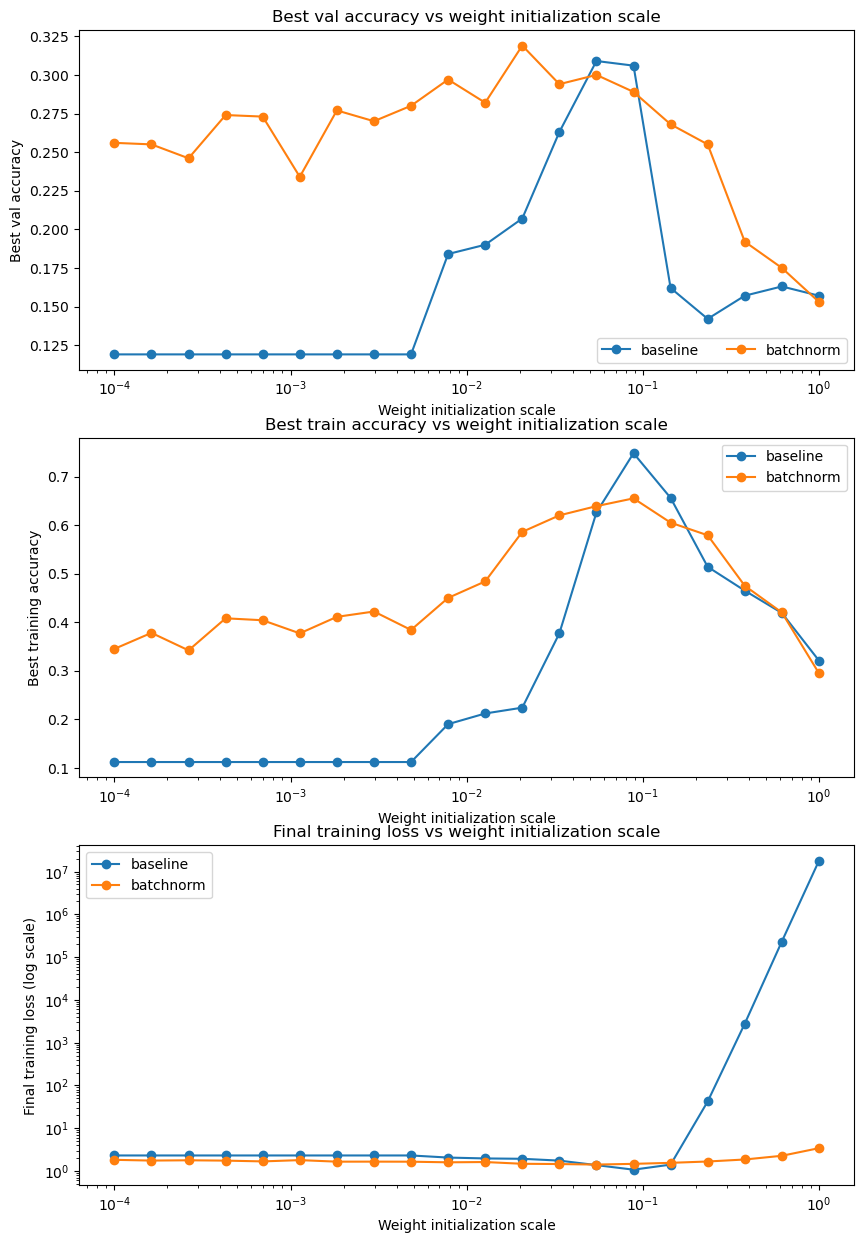

In [8]:
# Plot results of weight scale experiment
best_train_accs, bn_best_train_accs = [], []
best_val_accs, bn_best_val_accs = [], []
final_train_loss, bn_final_train_loss = [], []

for ws in weight_scales:
  best_train_accs.append(max(solvers[ws].train_acc_history))
  bn_best_train_accs.append(max(bn_solvers[ws].train_acc_history))
  
  best_val_accs.append(max(solvers[ws].val_acc_history))
  bn_best_val_accs.append(max(bn_solvers[ws].val_acc_history))
  
  final_train_loss.append(np.mean(solvers[ws].loss_history[-100:]))
  bn_final_train_loss.append(np.mean(bn_solvers[ws].loss_history[-100:]))
  
plt.subplot(3, 1, 1)
plt.title('Best val accuracy vs weight initialization scale')
plt.xlabel('Weight initialization scale')
plt.ylabel('Best val accuracy')
plt.semilogx(weight_scales, best_val_accs, '-o', label='baseline')
plt.semilogx(weight_scales, bn_best_val_accs, '-o', label='batchnorm')
plt.legend(ncol=2, loc='lower right')

plt.subplot(3, 1, 2)
plt.title('Best train accuracy vs weight initialization scale')
plt.xlabel('Weight initialization scale')
plt.ylabel('Best training accuracy')
plt.semilogx(weight_scales, best_train_accs, '-o', label='baseline')
plt.semilogx(weight_scales, bn_best_train_accs, '-o', label='batchnorm')
plt.legend()

plt.subplot(3, 1, 3)
plt.title('Final training loss vs weight initialization scale')
plt.xlabel('Weight initialization scale')
plt.ylabel('Final training loss (log scale)')
plt.yscale('log')
plt.semilogx(weight_scales, final_train_loss, '-o', label='baseline')
plt.semilogx(weight_scales, bn_final_train_loss, '-o', label='batchnorm')
plt.legend()

plt.gcf().set_size_inches(10, 15)
plt.show()

## Question:

In the cell below, summarize the findings of this experiment, and WHY these results make sense.

## Answer:

Batchnorm made the network less picky about the initial weight scale. In the first experiment, it reached 34.8% validation accuracy versus 31.5% for the baseline. In the scale experiment, the baseline stayed at 11.9% for very small weights and only worked well in a fairly narrow range around 0.03 to 0.09. Batchnorm still learned with those tiny initial weights and had its best validation accuracy of 31.9% near a scale of 0.021.

With small weights, repeated matrix multiplications can shrink the activations and gradients through the deep network. With large weights, the activations and scores can grow too much, which shows up as the baseline's huge loss on the right side of the plot. Batchnorm rescales the hidden activations using each minibatch's mean and variance, so these scale problems do not build up as much from layer to layer. Gamma and beta still let the network learn a useful scale and offset.

Batchnorm does not make initialization irrelevant: its performance also falls at the largest scales, and the output scores are not normalized. It also does not remove overfitting. The training accuracies are much higher than the validation accuracies because these experiments only use 1,000 training images.
